<a href="https://colab.research.google.com/github/dev-jotape/favela_environmental_trajectories/blob/main/scripts/3_explore_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 0 Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Working directory and packages

In [1]:
setwd("/content/drive/MyDrive/Yale_Environmental_Data_Science_2026-2027/favela_environmental_trajectories")

library(readr)
library(dplyr)
library(ggplot2)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




## 2. Read the data

In [5]:
pixels  <- read_csv("data/processed/2_favela_pixels_clean_pilot.csv",
                    col_types = cols(cd_fcu = col_character(), prev_group = col_character()))
favelas <- read_csv("data/processed/2_favela_urbanization_pilot.csv",
                    col_types = cols(cd_fcu = col_character()))

regime_levels <- c("Structured", "Partially Structured", "Unstructured")
pixels$regime  <- factor(pixels$regime,  levels = regime_levels)
favelas$regime <- factor(favelas$regime, levels = regime_levels)

dim(pixels)
dim(favelas)
head(favelas)

[1] 77264    51

[1] 1357   36

cd_fcu,nm_fcu,cd_mun,nm_mun,sigla_uf,regime,area_km2,population,wtr_idx,sanit_idx,⋯,urb_span,median_censored,n_converted,prev_forest,prev_mosaic_of_uses,prev_herbaceous_shrubby,prev_pasture,prev_water,prev_other_non_vegetated,prev_agriculture
<chr>,<chr>,<dbl>,<chr>,<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
35503080069,Jardim Miliunas,3550308,São Paulo,SP,Partially Structured,0.026,1159,0.9974501,0.4510280,⋯,0,TRUE,NA,NA,NA,NA,NA,NA,NA,NA
35503082222,Avenida Arraias do Araguaia,3550308,São Paulo,SP,Structured,0.010,333,1.0000000,0.9870093,⋯,0,TRUE,NA,NA,NA,NA,NA,NA,NA,NA
35503081646,Pavanas,3550308,São Paulo,SP,Structured,0.003,161,1.0000000,0.9787383,⋯,0,TRUE,NA,NA,NA,NA,NA,NA,NA,NA
35503081067,Jardim São Carlos / Gleba 2,3550308,São Paulo,SP,Structured,0.053,1335,0.9989001,0.9316589,⋯,0,TRUE,NA,NA,NA,NA,NA,NA,NA,NA
35503081121,Jardim Jaraguá II,3550308,São Paulo,SP,Partially Structured,0.008,260,0.9679516,0.6843692,⋯,0,TRUE,3,0,0.3333333,0,0.6666667,0,0,0
35503082104,Rua Antônio Rodrigues da Silva Júnior,3550308,São Paulo,SP,Structured,0.021,203,1.0000000,1.0000000,⋯,11,TRUE,7,0,1.0000000,0,0.0000000,0,0,0


## 3. Land cover groups

In [8]:
class_lookup <- read_csv("data/processed/2_class_lookup.csv")

year_cols <- grep("^y[0-9]{4}$", names(pixels), value = TRUE)

Rows: 41 Columns: 2
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (1): group
dbl (1): class

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [11]:
names(favelas)

[1] "cd_fcu"                   "nm_fcu"                  
 [3] "cd_mun"                   "nm_mun"                  
 [5] "sigla_uf"                 "regime"                  
 [7] "area_km2"                 "population"              
 [9] "wtr_idx"                  "sanit_idx"               
[11] "slope_10"                 "slope_20"                
[13] "slope_30"                 "slope_30p"               
[15] "hand_0_3"                 "hand_3_6"                
[17] "hand_6p"                  "n_pixels"                
[19] "share_never_urban"        "share_pre1985"           
[21] "urb_year_p25"             "urb_year_median"         
[23] "urb_year_p75"             "urban_share_1985"        
[25] "urban_share_2025"         "mean_reversals"          
[27] "urb_span"                 "median_censored"         
[29] "n_converted"              "prev_forest"             
[31] "prev_mosaic_of_uses"      "prev_herbaceous_shrubby" 
[33] "prev_pasture"             "prev_water"              
[35] "prev_other_non_vegetated" "prev_agriculture"

## 4. Favelas used in the analysis

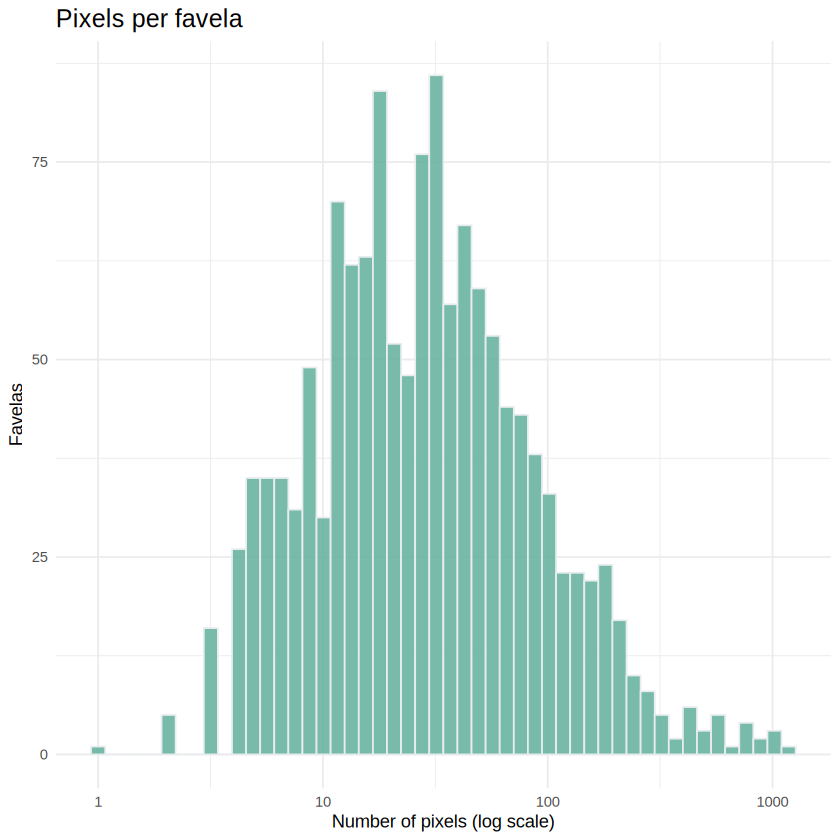

In [28]:
ggplot(favelas, aes(n_pixels)) +
  geom_histogram(fill="#69b3a2", color="#e9ecef", alpha=0.9, bins = 50) +
  scale_x_log10() +
  labs(title = "Pixels per favela", x = "Number of pixels (log scale)", y = "Favelas") +
  theme_minimal() +
  theme(
    plot.title = element_text(size=15)
  )

## 5. Land cover inside the favelas, 1985–2025

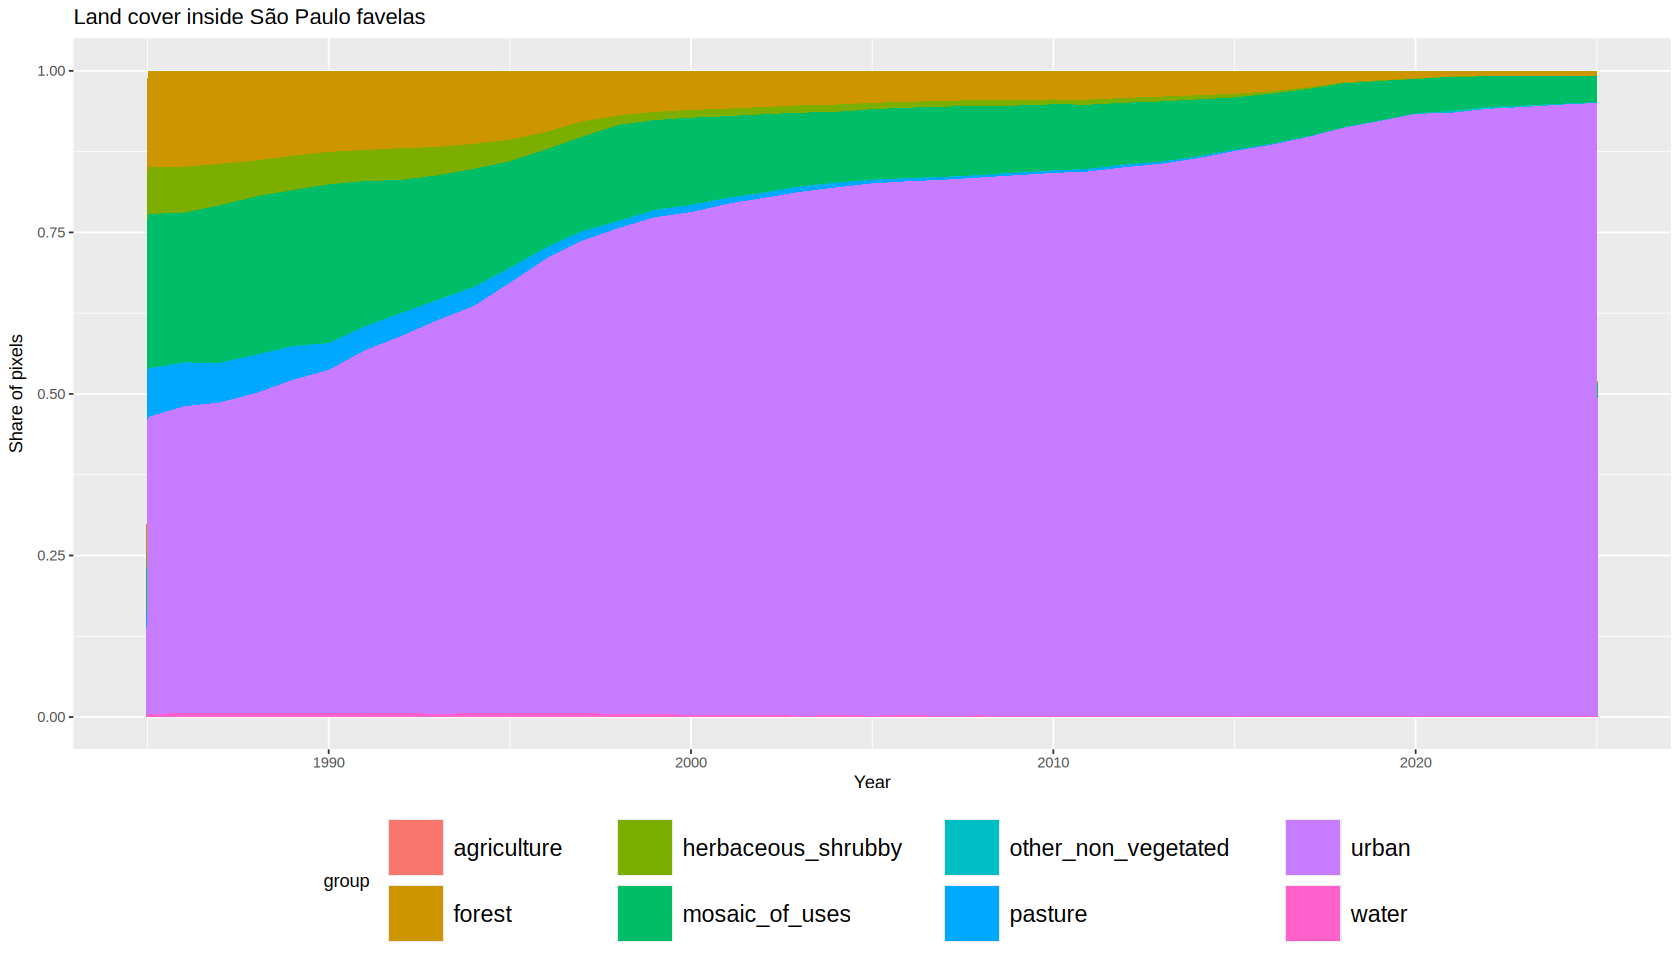

In [38]:
composition <- data.frame()

for (col in year_cols) {
  one_year <- tibble(class = pixels[[col]]) %>%
    left_join(class_lookup, by = "class") %>%
    count(group) %>%
    mutate(year = as.integer(sub("y", "", col)),
           share = n / sum(n))
  composition <- bind_rows(composition, one_year)
}

options(repr.plot.width = 14, repr.plot.height = 8)

ggplot(composition, aes(year, share, fill = group)) +
  geom_area() +
  labs(title = "Land cover inside São Paulo favelas", x = "Year", y = "Share of pixels") +
  theme(
    legend.position = "bottom",
    legend.text = element_text(size = 14),
    legend.key.size = unit(1.2, "cm")
  )




## 6. Urban share over time, by regime

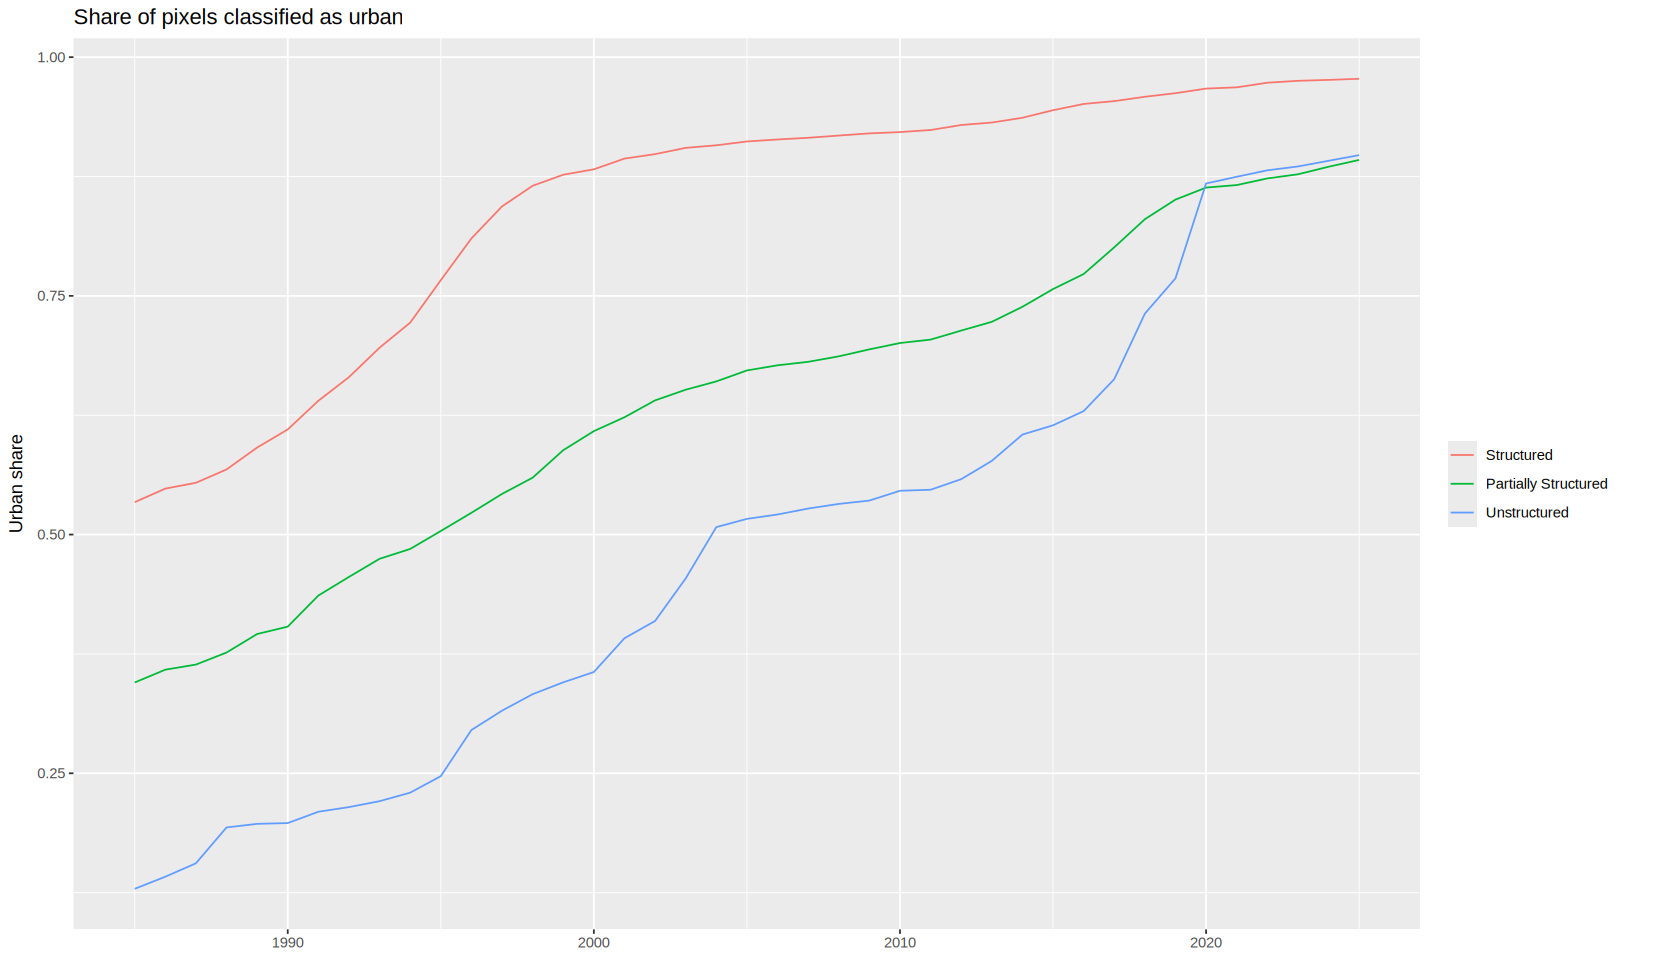

In [39]:
urban_by_regime <- data.frame()

for (col in year_cols) {
  one_year <- pixels %>%
    filter(!is.na(regime)) %>%
    group_by(regime) %>%
    summarise(urban_share = mean(.data[[col]] == 24)) %>%
    mutate(year = as.integer(sub("y", "", col)))
  urban_by_regime <- bind_rows(urban_by_regime, one_year)
}

ggplot(urban_by_regime, aes(year, urban_share, color = regime)) +
  geom_line() +
  labs(title = "Share of pixels classified as urban", x = NULL, y = "Urban share", color = NULL)

## 7. Period of urbanization

Favelas with median year 1985 were mostly urban before the series starts, so they form a **pre-1985** group.

In [41]:
favelas <- favelas %>%
  mutate(period = case_when(
    is.na(urb_year_median)  ~ "never urban",
    median_censored         ~ "pre-1985",
    urb_year_median <= 1999 ~ "1986-1999",
    urb_year_median <= 2009 ~ "2000-2009",
    TRUE                    ~ "2010-2025"
  ))

favelas %>% count(period)

period,n
<chr>,<int>
1986-1999,261
2000-2009,55
2010-2025,65
pre-1985,976


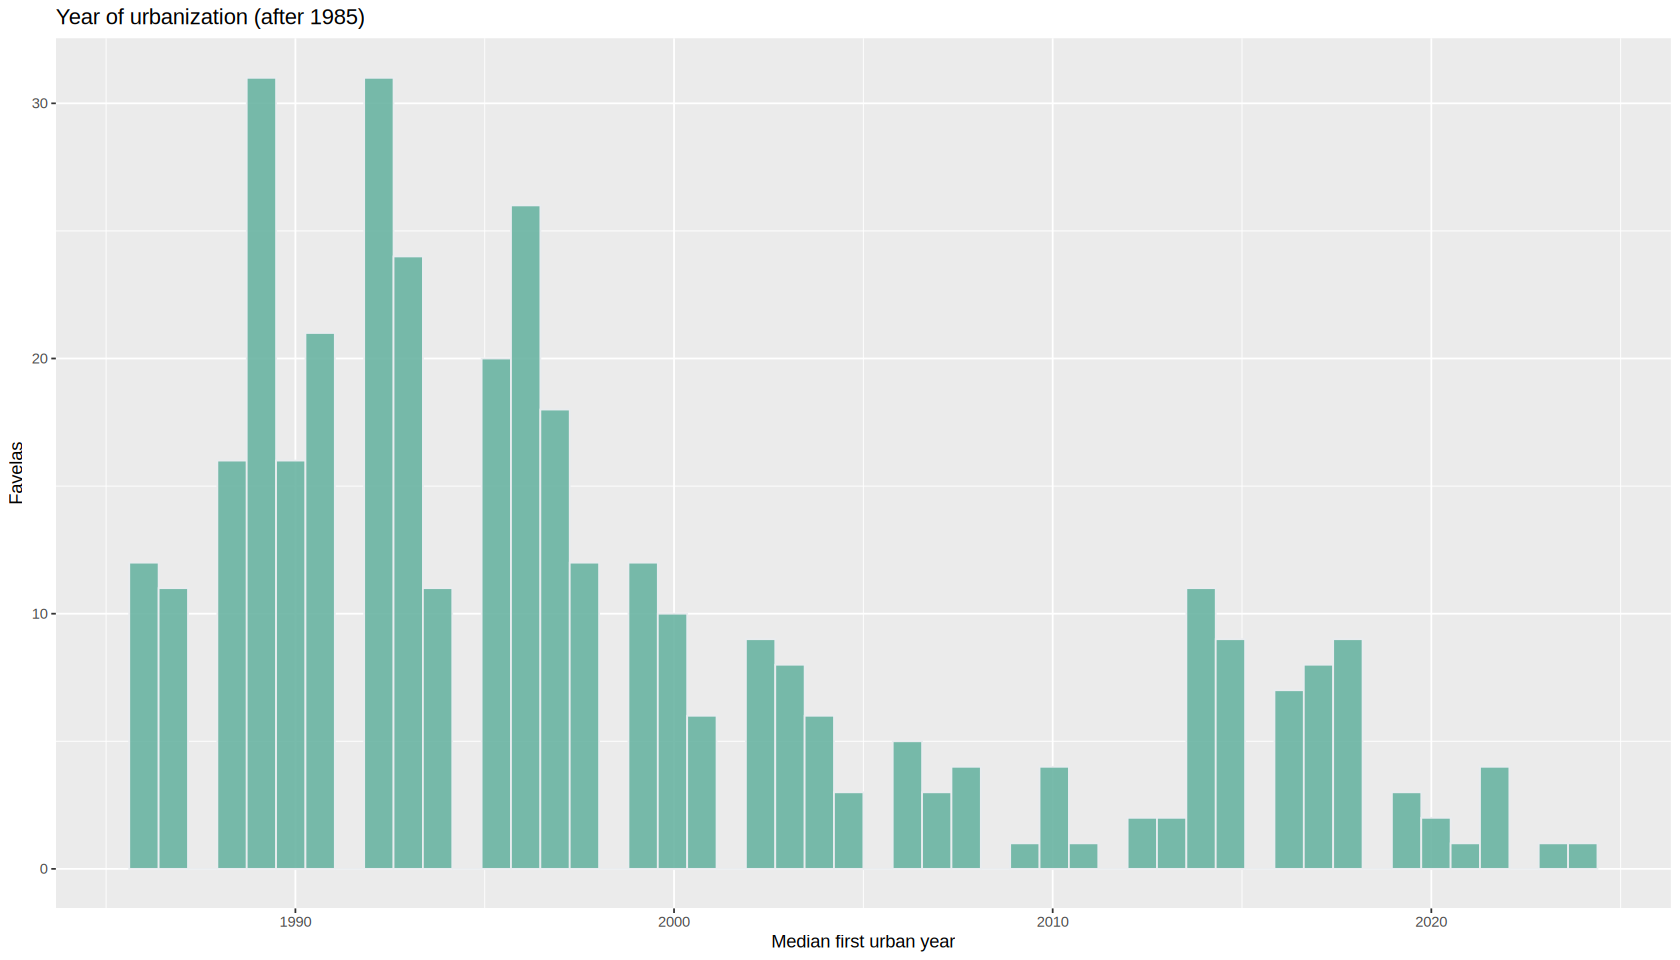

In [44]:
recent <- favelas %>% filter(period %in% c("1986-1999", "2000-2009", "2010-2025"))

ggplot(recent, aes(urb_year_median)) +
  geom_histogram(fill="#69b3a2", color="#e9ecef", alpha=0.9, bins = 50) +
  labs(title = "Year of urbanization (after 1985)", x = "Median first urban year", y = "Favelas")

## 8. Period of urbanization by regime

period,regime,n
<chr>,<fct>,<int>
1986-1999,Structured,179
1986-1999,Partially Structured,74
1986-1999,Unstructured,8
2000-2009,Structured,20
2000-2009,Partially Structured,29
2000-2009,Unstructured,6
2010-2025,Structured,18
2010-2025,Partially Structured,35
2010-2025,Unstructured,12


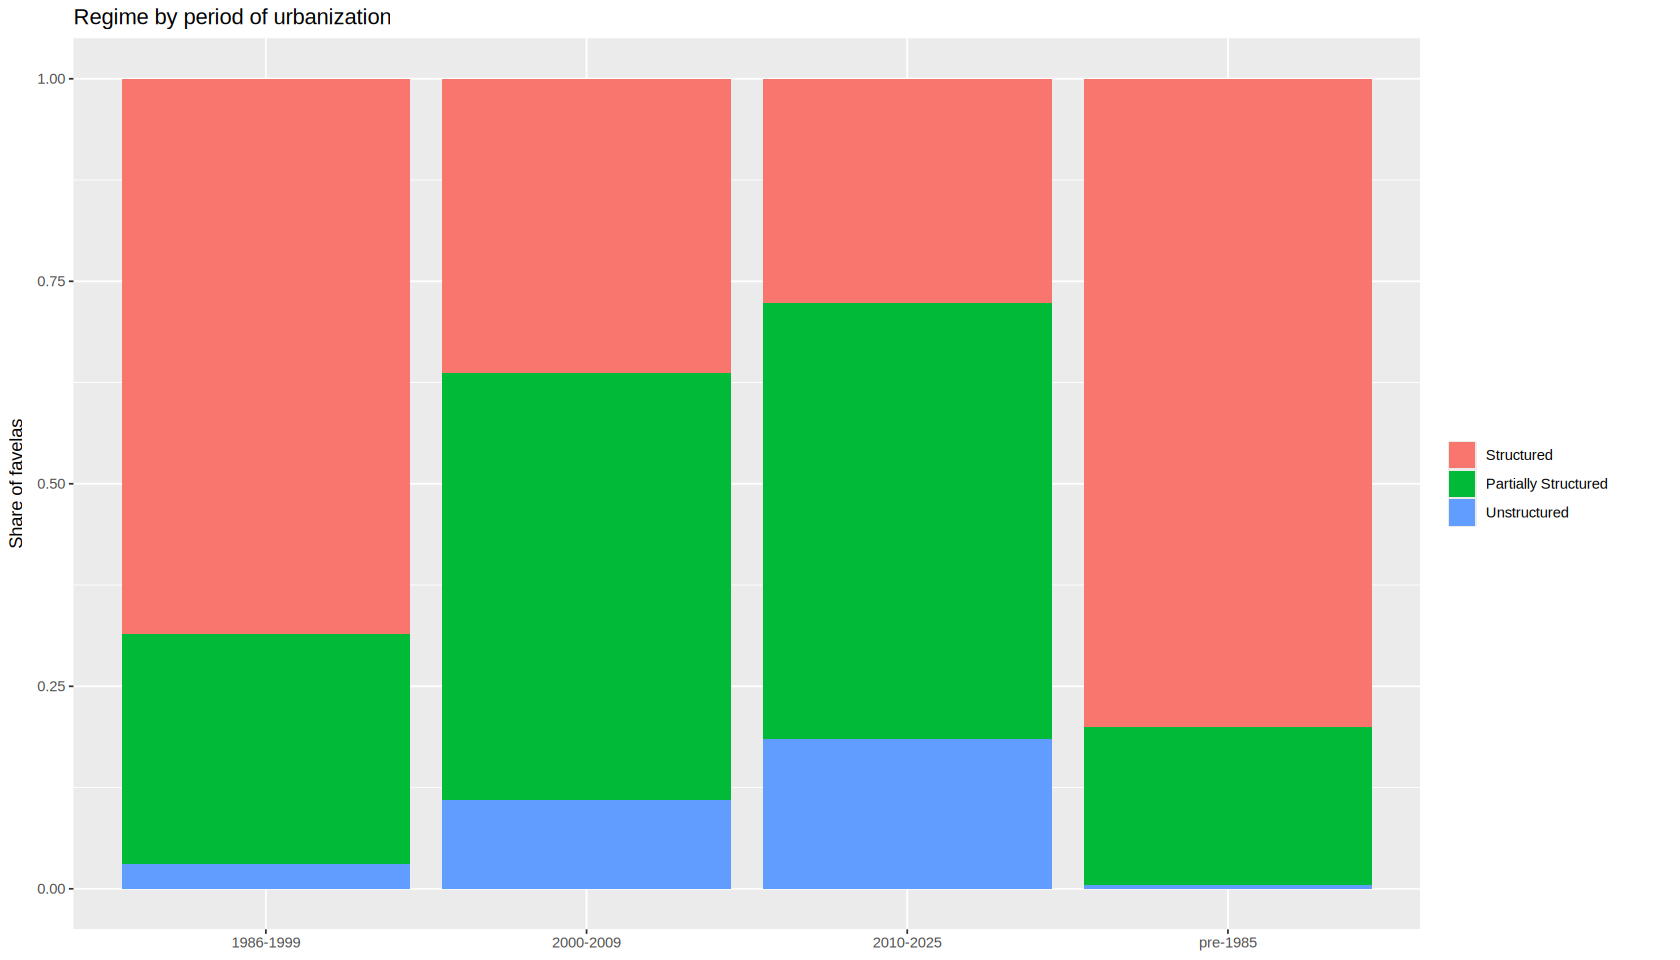

In [45]:
favelas %>% count(period, regime)

ggplot(favelas %>% filter(!is.na(regime)), aes(period, fill = regime)) +
  geom_bar(position = "fill") +
  labs(title = "Regime by period of urbanization", x = NULL, y = "Share of favelas", fill = NULL)

regime,favelas,median_year,median_span
<fct>,<int>,<dbl>,<dbl>
Structured,217,1994.0,5.0
Partially Structured,138,1999.0,6.5
Unstructured,26,2007.5,3.5


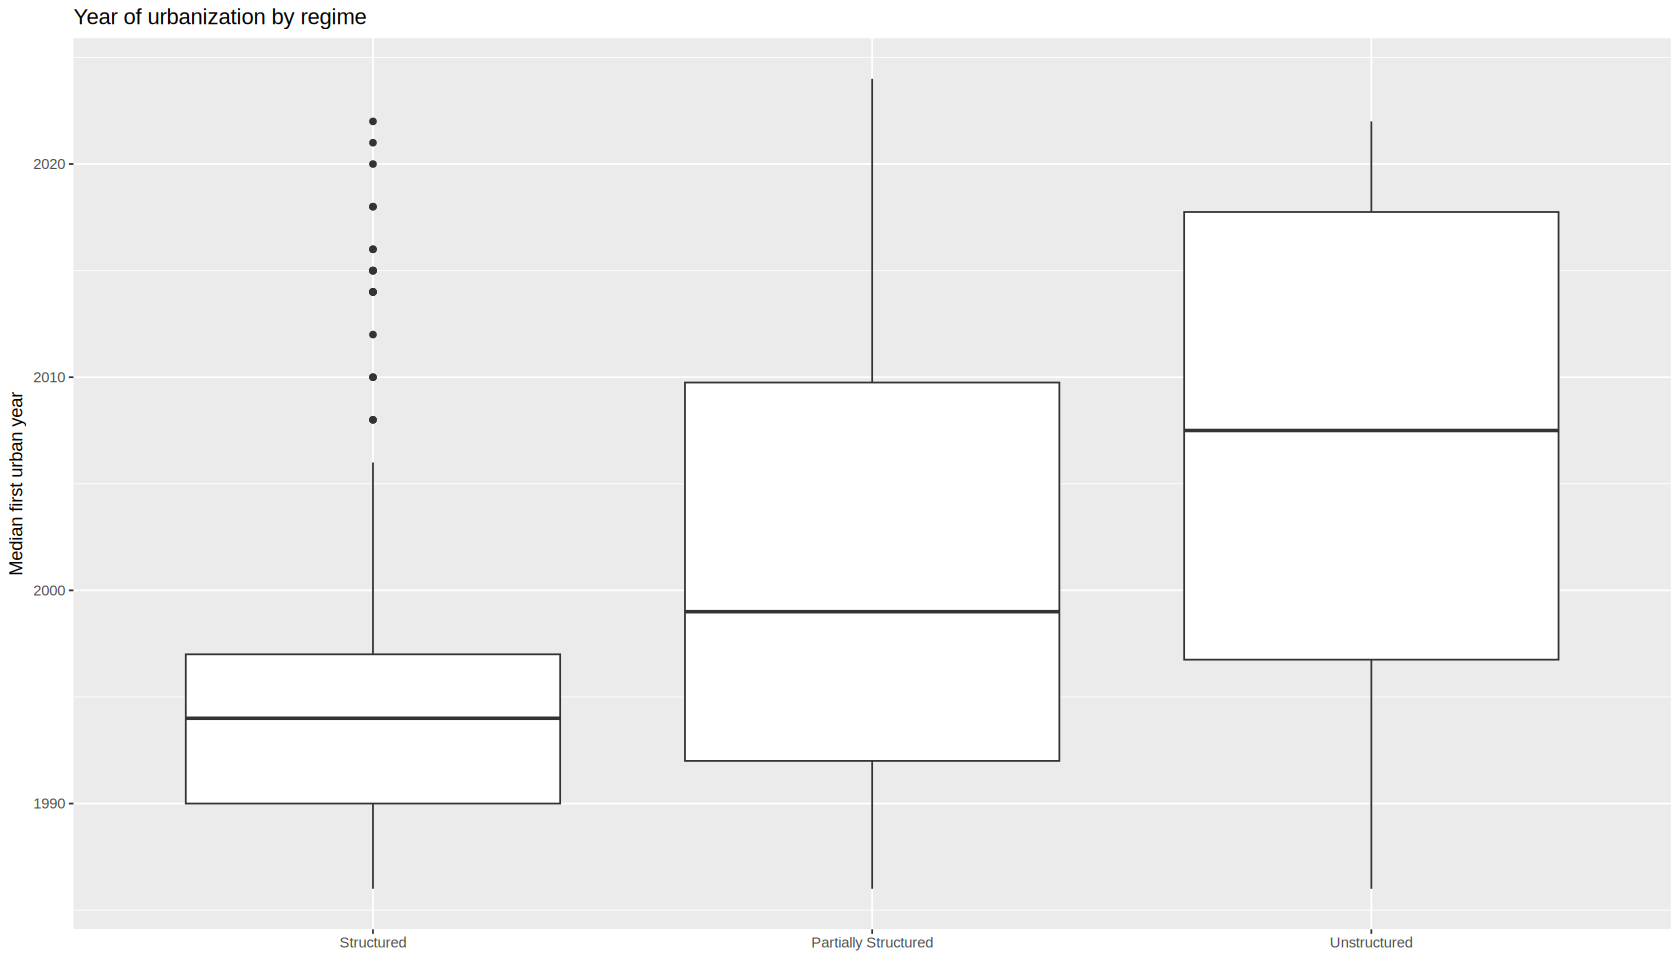

In [46]:
ggplot(recent %>% filter(!is.na(regime)), aes(regime, urb_year_median)) +
  geom_boxplot() +
  labs(title = "Year of urbanization by regime", x = NULL, y = "Median first urban year")

recent %>%
  group_by(regime) %>%
  summarise(favelas = n(),
            median_year = median(urb_year_median),
            median_span = median(urb_span, na.rm = TRUE))

## 9. Land cover before urbanization, by regime

regime,prev_group,n,share
<fct>,<chr>,<int>,<dbl>
Structured,forest,2615,0.1137302657
Structured,herbaceous_shrubby,2397,0.1042491193
Structured,mosaic_of_uses,16314,0.7095202888
Structured,other_non_vegetated,61,0.0026529813
Structured,pasture,1469,0.0638890097
Structured,water,137,0.0059583351
Partially Structured,agriculture,3,0.0002437241
Partially Structured,forest,1105,0.0897717118
Partially Structured,herbaceous_shrubby,902,0.0732797140


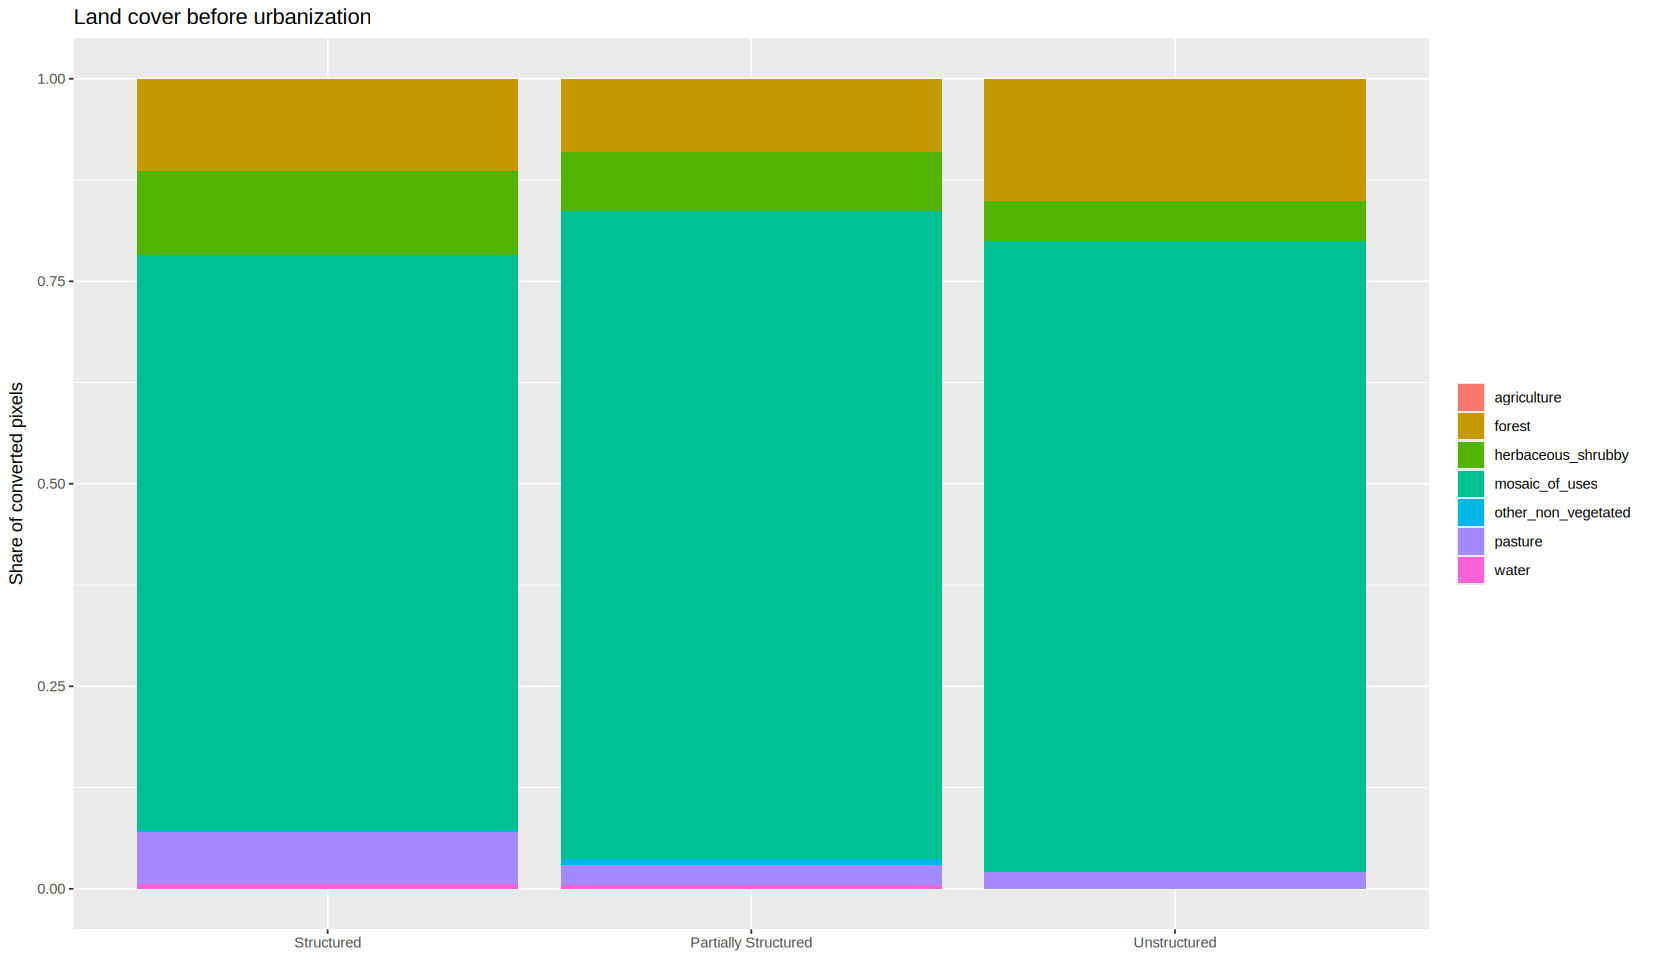

In [49]:
prev_by_regime <- pixels %>%
  filter(!is.na(prev_group), !is.na(regime)) %>%
  count(regime, prev_group) %>%
  group_by(regime) %>%
  mutate(share = n / sum(n))

prev_by_regime

ggplot(prev_by_regime, aes(regime, share, fill = prev_group)) +
  geom_col() +
  labs(title = "Land cover before urbanization", x = NULL, y = "Share of converted pixels", fill = NULL)

## 10. Terrain by period of urbanization

`hand_0_3`: % of area within 3 m of the nearest drainage (flood-prone). `slope_30p`: % of area with slope above 30%.

Warning message:
“Removed 12 rows containing non-finite outside the scale range
(`stat_boxplot()`).”
Warning message:
“Removed 12 rows containing non-finite outside the scale range
(`stat_boxplot()`).”


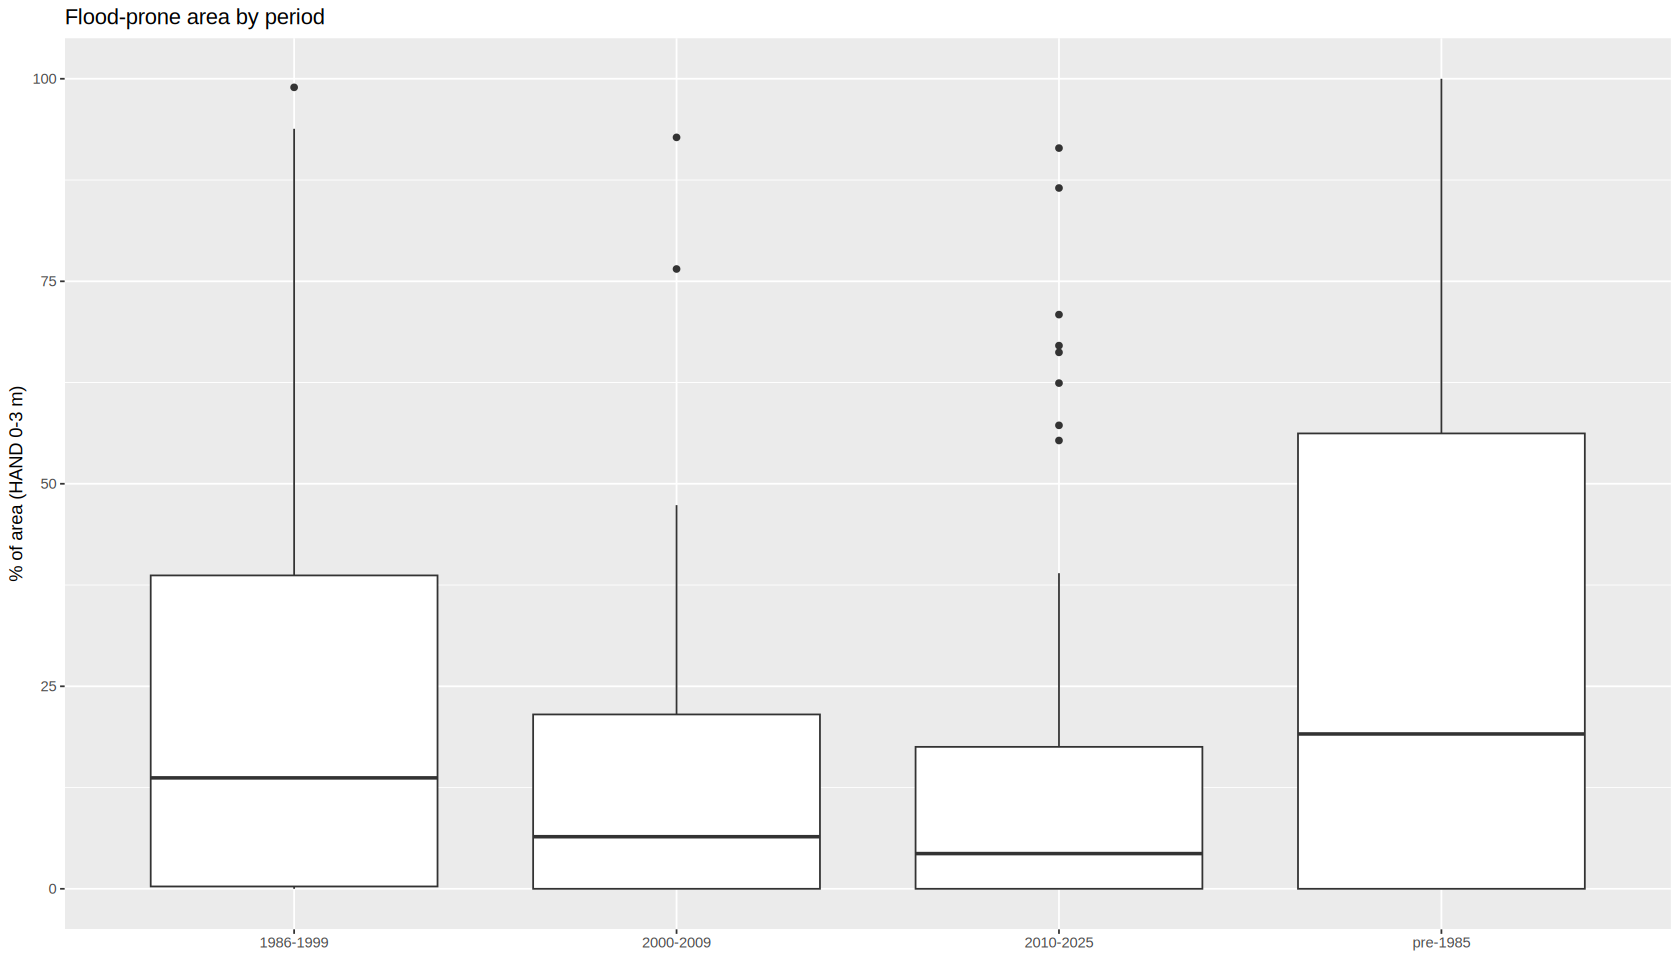

period,favelas,median_hand,median_slope
<chr>,<int>,<dbl>,<dbl>
1986-1999,261,13.694616,0
2000-2009,55,6.431269,0
2010-2025,65,4.347846,0
pre-1985,976,19.115838,0


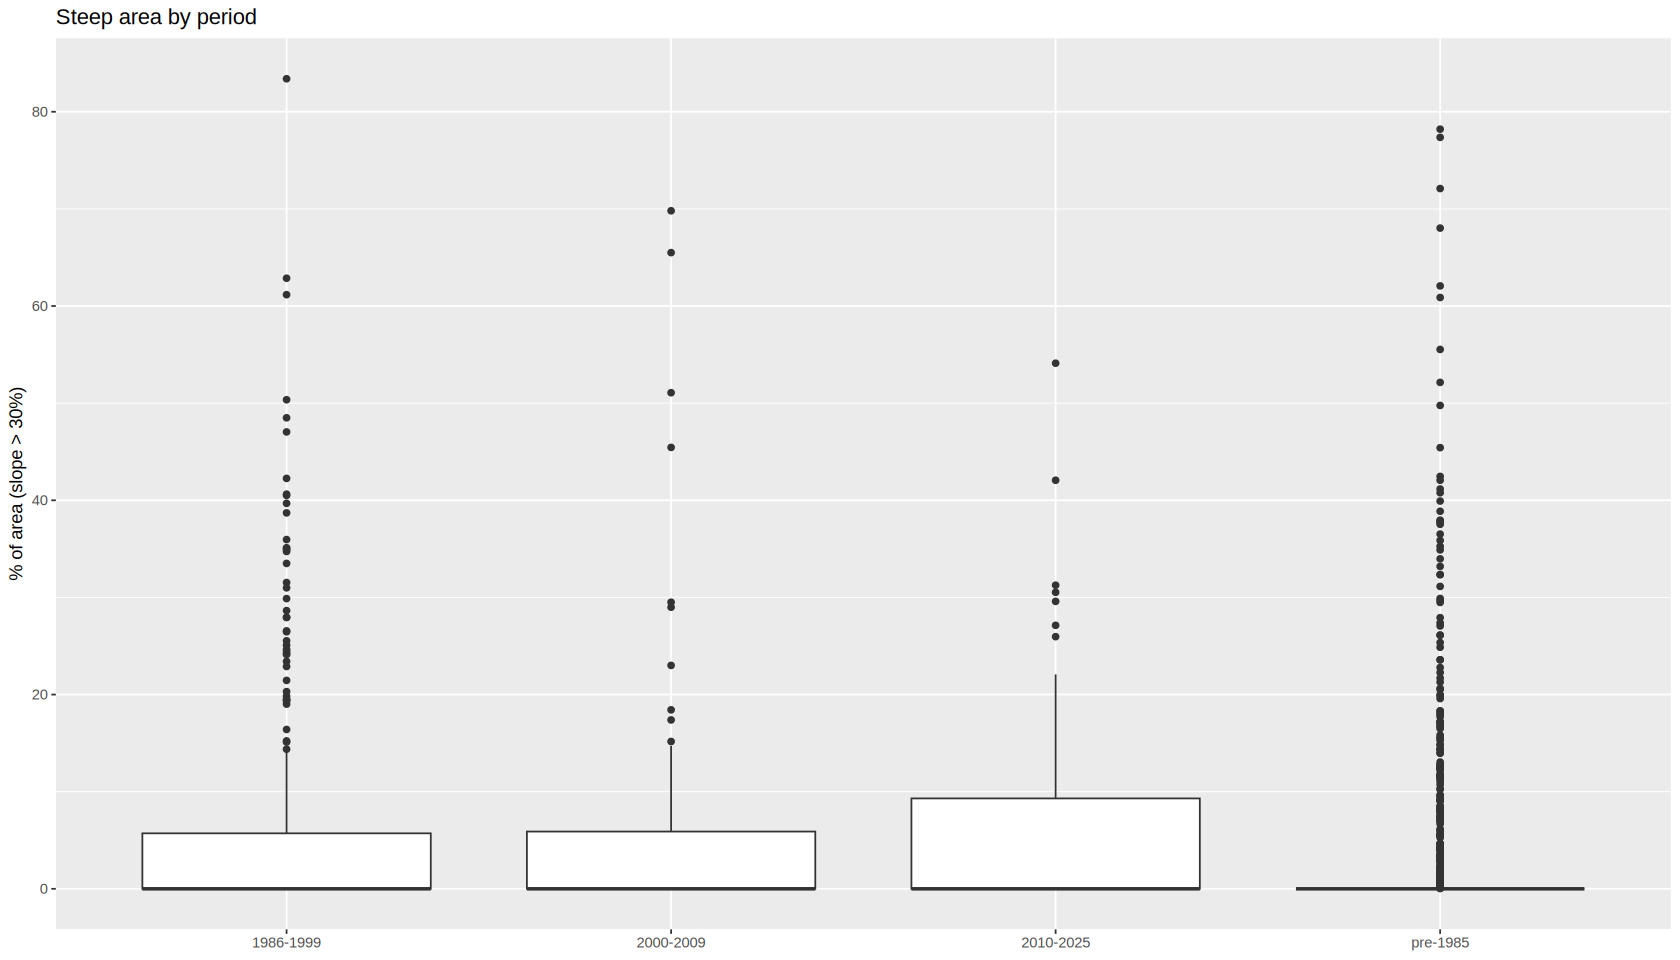

In [51]:
ggplot(favelas, aes(period, hand_0_3)) +
  geom_boxplot() +
  labs(title = "Flood-prone area by period", x = NULL, y = "% of area (HAND 0-3 m)")

ggplot(favelas, aes(period, slope_30p)) +
  geom_boxplot() +
  labs(title = "Steep area by period", x = NULL, y = "% of area (slope > 30%)")

favelas %>%
  group_by(period) %>%
  summarise(favelas = n(),
            median_hand = median(hand_0_3, na.rm = TRUE),
            median_slope = median(slope_30p, na.rm = TRUE))